<a href="https://colab.research.google.com/github/mehakgupta0406/marketing-ab-test-analysis/blob/main/Marketing_ab_testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business question
Does the conversion rate differ between users shown a marketing
advertisement and users shown a public service announcement (PSA)?

## Groups
- Ad group: users shown the marketing advertisement.
- PSA group: users shown a public service announcement.

## Primary metric
Conversion rate = number of converted users / total users in each group.

## Hypotheses
- Null hypothesis (H₀): The groups have equal conversion rates.
- Alternative hypothesis (H₁): The groups have different conversion rates.

## Statistical testing plan
- Use a two-sided two-proportion z-test to compare conversion rates.
- Use a significance level of 5% (α = 0.05).
- Calculate a 95% confidence interval for the difference
  in conversion rates (ad minus PSA).
- Assess statistical evidence alongside effect size and
  experiment limitations before drawing a business conclusion.

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("marketing_AB.csv")

In [3]:
df.shape

(336582, 7)

In [4]:
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20.0
1,1,1119715,ad,False,93,Tuesday,22.0
2,2,1144181,ad,False,21,Tuesday,18.0
3,3,1435133,ad,False,355,Tuesday,10.0
4,4,1015700,ad,False,276,Friday,14.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336582 entries, 0 to 336581
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Unnamed: 0     336582 non-null  int64  
 1   user id        336582 non-null  int64  
 2   test group     336582 non-null  object 
 3   converted      336582 non-null  bool   
 4   total ads      336582 non-null  int64  
 5   most ads day   336582 non-null  object 
 6   most ads hour  336581 non-null  float64
dtypes: bool(1), float64(1), int64(3), object(2)
memory usage: 15.7+ MB


In [6]:
df.drop("Unnamed: 0",axis=1,inplace=True)

In [7]:
df.shape

(336582, 6)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336582 entries, 0 to 336581
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user id        336582 non-null  int64  
 1   test group     336582 non-null  object 
 2   converted      336582 non-null  bool   
 3   total ads      336582 non-null  int64  
 4   most ads day   336582 non-null  object 
 5   most ads hour  336581 non-null  float64
dtypes: bool(1), float64(1), int64(2), object(2)
memory usage: 13.2+ MB


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336582 entries, 0 to 336581
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user id        336582 non-null  int64  
 1   test group     336582 non-null  object 
 2   converted      336582 non-null  bool   
 3   total ads      336582 non-null  int64  
 4   most ads day   336582 non-null  object 
 5   most ads hour  336581 non-null  float64
dtypes: bool(1), float64(1), int64(2), object(2)
memory usage: 13.2+ MB


In [12]:
df["user id"].duplicated().sum()

np.int64(0)

In [13]:
df['test group'].unique()

array(['ad', 'psa'], dtype=object)

In [14]:
import sqlite3

In [15]:
conn = sqlite3.connect(":memory:")

In [16]:
df.to_sql("marketing_ab", conn, index=False, if_exists="replace")

336582

In [17]:
query="""
Select "test group" as test_group, Count(*) as no_of_users from marketing_ab group by "test group" """

In [18]:
pd.read_sql_query(query, conn)

,test_group,no_of_users
0,ad,323351
1,psa,13231


In [19]:
query="""
Select "test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion from marketing_ab group by "test group" """

In [20]:
pd.read_sql_query(query, conn)

,test_group,no_of_users,conversion
0,ad,323351,12162
1,psa,13231,328


In [21]:
query="""
Select "test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion ,100.0*(SUM(converted))/Count(*) as conversion_rate from marketing_ab group by "test group" """

In [22]:
pd.read_sql_query(query, conn)

,test_group,no_of_users,conversion,conversion_rate
0,ad,323351,12162,3.761238
1,psa,13231,328,2.479027


In [23]:
result=pd.read_sql_query(query, conn).set_index("test_group")

In [24]:
absolutelift=(result.loc["ad","conversion_rate"]-result.loc["psa","conversion_rate"])

In [25]:
print(f"{absolutelift:.2f} absolute lift")

1.28 absolute lift


In [26]:
relative_lift=absolutelift/result.loc["psa","conversion_rate"]*100

In [27]:
print(f"{relative_lift:.2f}%")

51.72%


In [28]:
from statsmodels.stats.proportion import proportions_ztest

conversions = result.loc[["ad", "psa"], "conversion"].to_numpy()
users = result.loc[["ad", "psa"], "no_of_users"].to_numpy()

z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject H₀: evidence that the conversion rates differ.")
else:
    print("Fail to reject H₀: insufficient evidence that the rates differ.")

Z-statistic: 7.648
P-value: 2.048e-14
Reject H₀: evidence that the conversion rates differ.


The two-sided two-proportion z-test found evidence of a
difference in conversion rates (z = 7.370, p < 0.001).

The ad group converted at 2.55%, compared with 1.79% for
the PSA group—an observed increase of 0.77 percentage points.

This result is statistically significant. Causal interpretation
depends on valid experiment design, and profitability requires
cost and conversion-value information.

In [29]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    count1=int(conversions[0]),
    nobs1=int(users[0]),
    count2=int(conversions[1]),
    nobs2=int(users[1]),
    compare="diff",
    method="newcomb",
    alpha=0.05
)

difference = conversions[0] / users[0] - conversions[1] / users[1]

print(f"Observed difference: {difference * 100:.3f} percentage points")
print(
    f"95% confidence interval: "
    f"{ci_low * 100:.3f} to {ci_high * 100:.3f} percentage points"
)

Observed difference: 1.282 percentage points
95% confidence interval: 0.996 to 1.542 percentage points


The ad group's conversion rate was 0.769 percentage points
higher than the PSA group's rate (95% confidence interval:
0.587 to 0.936 percentage points).

The interval excludes zero, consistent with the hypothesis
test's evidence of a difference between the groups.

In [30]:
import matplotlib.pyplot as plt

In [31]:
ad_rate = result.loc["ad", "conversion_rate"]
psa_rate = result.loc["psa", "conversion_rate"]

print(ad_rate)
print(psa_rate)

3.7612377880383856
2.479026528607059


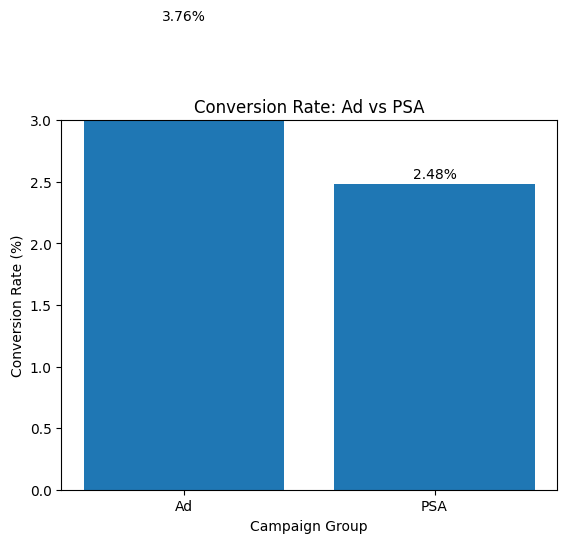

In [32]:
plt.bar(["Ad", "PSA"], [ad_rate, psa_rate])
plt.title("Conversion Rate: Ad vs PSA")
plt.xlabel("Campaign Group")
plt.ylabel("Conversion Rate (%)")
plt.text(0, ad_rate + 0.05, f"{ad_rate:.2f}%", ha="center")
plt.text(1, psa_rate + 0.05, f"{psa_rate:.2f}%", ha="center")
plt.ylim(0, 3)
plt.savefig("conversion_rates.png", dpi=300, bbox_inches="tight")
plt.show()

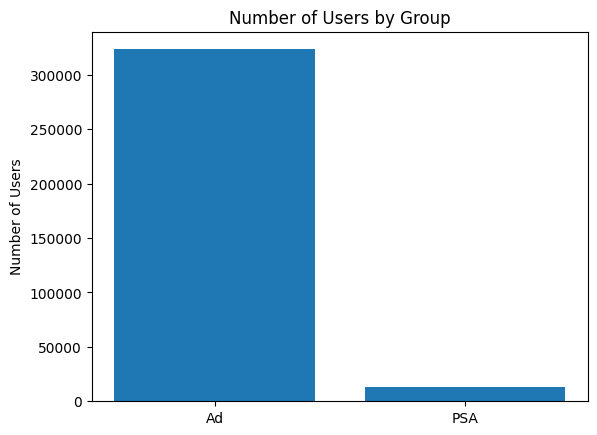

In [33]:
plt.bar(["Ad", "PSA"], users)

plt.title("Number of Users by Group")
plt.ylabel("Number of Users")

plt.show()

The ad group contains 564,577 users (96%), while the PSA
group contains 23,524 users (4%).

The intended allocation is unavailable, so we cannot confirm
whether this split matches the experiment design.

In [34]:
from google.colab import files

files.download("conversion_rates.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Business conclusion

The ad group had a conversion rate of 2.55%, compared with
1.79% for the PSA group.

The estimated increase was 0.769 percentage points
(95% confidence interval: 0.587–0.936), with a relative lift
of 43.09%. The difference was statistically significant
(p < 0.001).

These findings support further evaluation of the advertising
campaign. Before increasing spending, confirm the validity
of group assignment and compare campaign costs with the
value of additional conversions.

## Limitations

- Random assignment cannot be independently verified from
  the dataset alone, limiting causal conclusions.
- The groups have unequal sizes. The intended allocation
  is needed to check whether this was expected.
- Campaign costs and conversion values are unavailable,
  so profitability cannot be assessed.
- Results from this dataset may not generalize to other
  campaigns or audiences.

In [35]:
import pandas
import matplotlib
import statsmodels

print("pandas:", pandas.__version__)
print("matplotlib:", matplotlib.__version__)
print("statsmodels:", statsmodels.__version__)

pandas: 2.2.3
matplotlib: 3.10.0
statsmodels: 0.15.0


In [38]:
day_query="""
Select "most ads day" as day ,"test group" as test_group, Count(*) as no_of_users , SUM(converted) as conversion ,100.0*(SUM(converted))/Count(*) as conversion_rate from marketing_ab group by "most ads day", "test group" """

In [40]:
day_result = pd.read_sql_query(day_query, conn)

In [42]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

In [43]:
print("Day and group summary:")
print(
    day_result.set_index(["day", "test_group"])
    .reindex(day_order, level="day")
    .round(2)
)

Day and group summary:
                      no_of_users  conversion  conversion_rate
day       test_group                                          
Monday    ad                50401        2358             4.68
          psa                1853          62             3.35
Tuesday   ad                43811        1906             4.35
          psa                1573          32             2.03
Wednesday ad                43051        1645             3.82
          psa                2015          43             2.13
Thursday  ad                43495        1387             3.19
          psa                2421          55             2.27
Friday    ad                54494        1648             3.02
          psa                2157          49             2.27
Saturday  ad                43388        1476             3.40
          psa                1526          34             2.23
Sunday    ad                44710        1742             3.90
          psa                168

In [44]:
day_comparison = day_result.pivot(
    index="day",
    columns="test_group",
    values="conversion_rate"
).reindex(day_order)

In [45]:
day_comparison

test_group,ad,psa
day,,
Monday,4.678479,3.345926
Tuesday,4.350506,2.034329
Wednesday,3.821049,2.133995
Thursday,3.188872,2.271789
Friday,3.024186,2.271674
Saturday,3.401862,2.228047
Sunday,3.896220,3.143535


In [46]:
day_comparison["difference_pp"] = (
    day_comparison["ad"] - day_comparison["psa"]
)

In [47]:
day_comparison["difference_pp"]

,difference_pp
day,
Monday,1.332553
Tuesday,2.316176
Wednesday,1.687054
Thursday,0.917084
Friday,0.752513
Saturday,1.173815
Sunday,0.752685
